# 3D Prijsvoorspellingen en investeren

Hieronder worden tijdsreeksen van een aandeel gebruikt om een beleggingsstrategie uit te werken (noot: dit is GEEN ECHT beleggingsadvies en dient enkel ter illustratie van Python, NumPy en Pandas). We gebruiken hiervoor de ticker `AAPL` voor Apple Inc.

## Importeren van de data

We laden de data in van een bestand (die komt van Yahoo Finance: https://finance.yahoo.com/quote/AAPL), we hebben verschillende kolommen voor de observatiedag, openingsprijs ('Open'), hoogste prijs die dag ('High'), etc. Wij richten ons enkel op de prijs bij sluiting ('Close'):

In [1]:
import pandas as pd

dfin = pd.read_csv('stock_df.csv')
dfin

,Date,Open,High,Low,Close,Volume,Dividends,Stock Splits
0,2018-01-02 00:00:00-05:00,40.030313,40.533750,39.818585,40.524338,102223600,0.0,0.0
1,2018-01-03 00:00:00-05:00,40.587864,41.063072,40.453773,40.517288,118071600,0.0,0.0
2,2018-01-04 00:00:00-05:00,40.590208,40.808994,40.481995,40.705482,89738400,0.0,0.0
3,2018-01-05 00:00:00-05:00,40.801947,41.255979,40.710199,41.168938,94640000,0.0,0.0
4,2018-01-08 00:00:00-05:00,41.016010,41.312425,40.917202,41.016010,82271200,0.0,0.0
...,...,...,...,...,...,...,...,...
1504,2023-12-22 00:00:00-05:00,194.228458,194.457347,192.029240,192.656174,37122800,0.0,0.0
1505,2023-12-26 00:00:00-05:00,192.666124,192.944757,191.889928,192.108856,28919300,0.0,0.0
1506,2023-12-27 00:00:00-05:00,191.551603,192.556674,190.158419,192.208374,48087700,0.0,0.0
1507,2023-12-28 00:00:00-05:00,193.193559,193.711028,192.228287,192.636292,34049900,0.0,0.0


De data heeft een index die niet gebruikt is, namelijk de datum. We kunnen de index aanpassen door ze gelijk te stellen aan de kolom 'Date'. Die moeten we nog omzetten in het datatype `datetime` via de functie `to_datetime()`. Vanaf dan is onze data tijdsreeksdata:

In [2]:
dfin.index = dfin['Date']
dfin = dfin.drop(['Date'], axis=1)
dfin.index = pd.to_datetime(dfin.index)
dfin

C:\Users\u0092789\AppData\Local\Temp\ipykernel_32456\4087697697.py:3: FutureWarning: In a future version of pandas, parsing datetimes with mixed time zones will raise an error unless `utc=True`. Please specify `utc=True` to opt in to the new behaviour and silence this warning. To create a `Series` with mixed offsets and `object` dtype, please use `apply` and `datetime.datetime.strptime`
  dfin.index = pd.to_datetime(dfin.index)


,Open,High,Low,Close,Volume,Dividends,Stock Splits
Date,,,,,,,
2018-01-02 00:00:00-05:00,40.030313,40.533750,39.818585,40.524338,102223600,0.0,0.0
2018-01-03 00:00:00-05:00,40.587864,41.063072,40.453773,40.517288,118071600,0.0,0.0
2018-01-04 00:00:00-05:00,40.590208,40.808994,40.481995,40.705482,89738400,0.0,0.0
2018-01-05 00:00:00-05:00,40.801947,41.255979,40.710199,41.168938,94640000,0.0,0.0
2018-01-08 00:00:00-05:00,41.016010,41.312425,40.917202,41.016010,82271200,0.0,0.0
...,...,...,...,...,...,...,...
2023-12-22 00:00:00-05:00,194.228458,194.457347,192.029240,192.656174,37122800,0.0,0.0
2023-12-26 00:00:00-05:00,192.666124,192.944757,191.889928,192.108856,28919300,0.0,0.0
2023-12-27 00:00:00-05:00,191.551603,192.556674,190.158419,192.208374,48087700,0.0,0.0


Veel analyses gebeuren met een 'rolling window'/voortschrijdend gemiddelde, waarbij het gemiddelde berekend wordt over de voorbije X periodes om zo een weergave te hebben van de reeks zonder extreme pieken. Het resultaat is dus een tijdsreeks met een gelijdelijker verloop (die hopelijk representatiever is). Hieronder wordt de rolling window per X=2 observaties gemaakt. Dit is niet te berekenen voor de eerste observatie, die geen vorige periode had:

In [3]:
dfin['Close_sma'] = dfin['Close'].rolling(2).mean()
dfin.head(10)

,Open,High,Low,Close,Volume,Dividends,Stock Splits,Close_sma
Date,,,,,,,,
2018-01-02 00:00:00-05:00,40.030313,40.533750,39.818585,40.524338,102223600,0.0,0.0,NaN
2018-01-03 00:00:00-05:00,40.587864,41.063072,40.453773,40.517288,118071600,0.0,0.0,40.520813
2018-01-04 00:00:00-05:00,40.590208,40.808994,40.481995,40.705482,89738400,0.0,0.0,40.611385
2018-01-05 00:00:00-05:00,40.801947,41.255979,40.710199,41.168938,94640000,0.0,0.0,40.937210
2018-01-08 00:00:00-05:00,41.016010,41.312425,40.917202,41.016010,82271200,0.0,0.0,41.092474
2018-01-09 00:00:00-05:00,41.063074,41.183050,40.794888,41.011318,86336000,0.0,0.0,41.013664
2018-01-10 00:00:00-05:00,40.736076,41.004262,40.698435,41.001907,95839600,0.0,0.0,41.006613
2018-01-11 00:00:00-05:00,41.072475,41.284203,41.048952,41.234798,74670800,0.0,0.0,41.118353
2018-01-12 00:00:00-05:00,41.446535,41.724133,41.321852,41.660614,101672400,0.0,0.0,41.447706


Hieronder worden een aantal voortschrijdende gemiddeldes meegegeven voor verschillende tijdspannes (X=10/40/100 dagen) om een inzicht te krijgen van de algemene beweging van de tijdsreeks/afsluitprijs ('Close') over tijd:

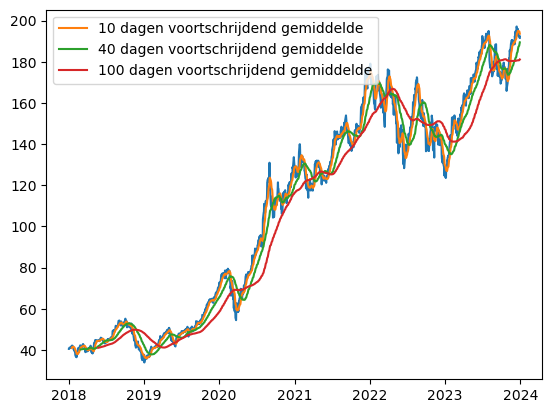

In [4]:
import matplotlib.pyplot as plt
import numpy as np

plt.plot(dfin['Close'])

for i in [10, 40, 100]:
    dfin[f'Close_sma_{i}'] = dfin['Close'].rolling(i).mean()
    plt.plot(dfin[f'Close_sma_{i}'], label=f'{i} dagen voortschrijdend gemiddelde')
plt.legend()
plt.show()

We gaan hieronder enkele strategieën toepassen. We berekenen nu eerst de dagelijkse opbrengst (want we gebruiken dagelijkse data). De opbrengst is het percentage positieve/negatieve groei tussen de huidige waarde en de vorige waarde (via `.shift(1)`):

In [5]:
dfin['Close'].head()

Date
2018-01-02 00:00:00-05:00    40.524338
2018-01-03 00:00:00-05:00    40.517288
2018-01-04 00:00:00-05:00    40.705482
2018-01-05 00:00:00-05:00    41.168938
2018-01-08 00:00:00-05:00    41.016010
Name: Close, dtype: float64

Merk op, de eerste rij heeft dan geen waarde meer:

In [6]:
dfin['Close'].shift(1).head()

Date
2018-01-02 00:00:00-05:00          NaN
2018-01-03 00:00:00-05:00    40.524338
2018-01-04 00:00:00-05:00    40.517288
2018-01-05 00:00:00-05:00    40.705482
2018-01-08 00:00:00-05:00    41.168938
Name: Close, dtype: float64

Hier voegen we de opbrengst toe als een aparte kolom:

In [7]:
dfin['Opbrengst'] = dfin['Close'] / dfin['Close'].shift(1)
dfin['Opbrengst']

Date
2018-01-02 00:00:00-05:00         NaN
2018-01-03 00:00:00-05:00    0.999826
2018-01-04 00:00:00-05:00    1.004645
2018-01-05 00:00:00-05:00    1.011386
2018-01-08 00:00:00-05:00    0.996285
                               ...   
2023-12-22 00:00:00-05:00    0.994453
2023-12-26 00:00:00-05:00    0.997159
2023-12-27 00:00:00-05:00    1.000518
2023-12-28 00:00:00-05:00    1.002226
2023-12-29 00:00:00-05:00    0.994576
Name: Opbrengst, Length: 1509, dtype: float64

Deze wordt meestal logaritmisch omgevormd om een verdeling met mooiere schaal en vorm te bekomen. De opbrengst volgt wel al een redelijk normale verdeling (dit is anders bij meer volatiele aandelen):

<Axes: >

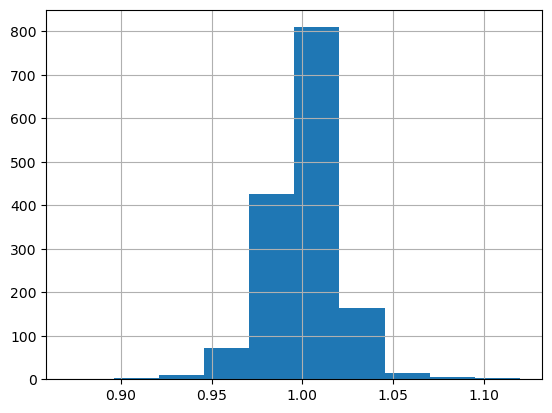

In [8]:
dfin['Log_opbrengst'] = np.log(dfin['Opbrengst'])
dfin['Opbrengst'].hist()

<Axes: >

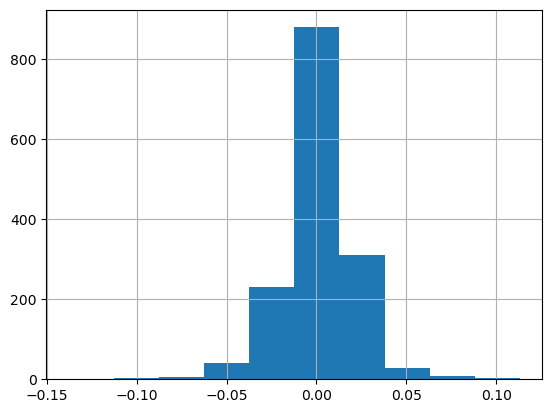

In [9]:
dfin['Log_opbrengst'].hist()

## Strategie uitwerken

Eerder zagen we dat de groene lijn (rolling window gemiddelde over 40 dagen) soms boven de rode lijn (rolling window gemiddelde over 100 dagen) komt te liggen en er soms ondergaat. Dit duidt erop dat de prijs soms sneller omhoog gaat dan gemiddeld over een lange period en dat de prijs dus systematisch sneller aan het stijgen is op korte termijn, of net daalt wanneer de groene onder de rode komt te liggen. Hierop kunnen we een simpele moving average crossover strategy toepassen door op te slaan wanneer het kortestermijngemiddelde boven het langetermijnsgemiddelde ligt:

Date
2018-05-24 00:00:00-04:00    1
2018-05-25 00:00:00-04:00    1
2018-05-29 00:00:00-04:00    1
2018-05-30 00:00:00-04:00    1
2018-05-31 00:00:00-04:00    1
                            ..
2023-12-22 00:00:00-05:00    1
2023-12-26 00:00:00-05:00    1
2023-12-27 00:00:00-05:00    1
2023-12-28 00:00:00-05:00    1
2023-12-29 00:00:00-05:00    1
Name: Positie, Length: 1410, dtype: int64

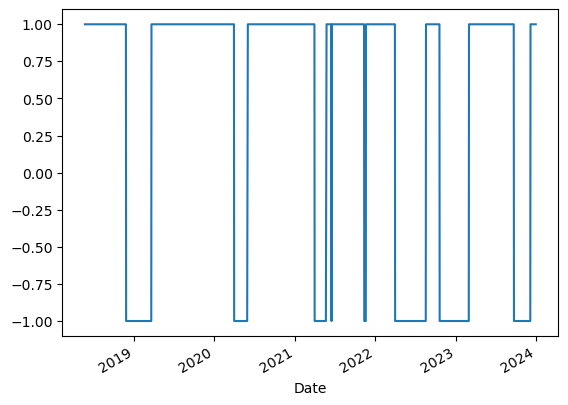

In [10]:
# 1: kortetermijn boven lange termijn
# -1: kortetermijn onder lange termijn
dfin['Positie'] = np.where(dfin['Close_sma_40'] > dfin['Close_sma_100'], 1, -1)
dfin.dropna(inplace=True)
dfin['Positie'].plot()
dfin['Positie']

Ook kunnen we de exacte crossoverpunten opslaan voor de visualisatie hieronder. Met `diff()` berekenen we het verschil tussen 2 opeenvolgende rijen. We krijgen ofwel een blijvende daling (-1-(1)=-2), ofwel een omschakeling (1-(-1)=2):

Date
2018-05-24 00:00:00-04:00    NaN
2018-05-25 00:00:00-04:00    0.0
2018-05-29 00:00:00-04:00    0.0
2018-05-30 00:00:00-04:00    0.0
2018-05-31 00:00:00-04:00    0.0
                            ... 
2023-12-22 00:00:00-05:00    0.0
2023-12-26 00:00:00-05:00    0.0
2023-12-27 00:00:00-05:00    0.0
2023-12-28 00:00:00-05:00    0.0
2023-12-29 00:00:00-05:00    0.0
Name: Aanpassing, Length: 1410, dtype: float64

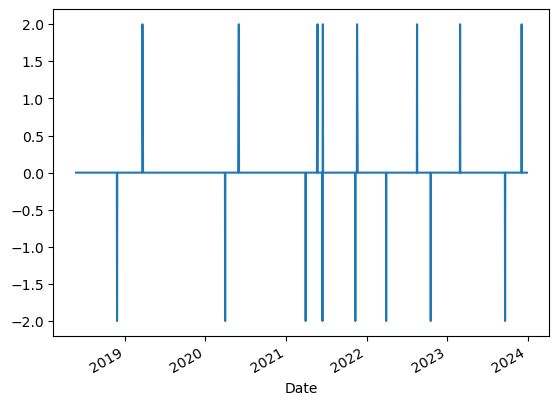

In [11]:
dfin['Aanpassing'] = dfin['Positie'].diff()
dfin['Aanpassing'].plot()
dfin['Aanpassing']

<Axes: xlabel='Date'>

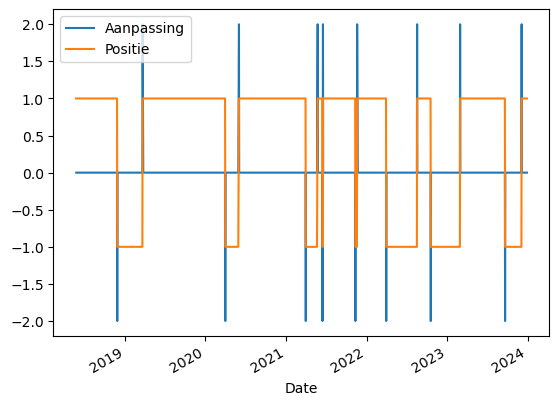

In [12]:
dfin[['Aanpassing', 'Positie']].plot()

In [13]:
dfin['Aanpassing'].value_counts()

Aanpassing
 0.0    1393
-2.0       8
 2.0       8
Name: count, dtype: int64

Als we onze strategie volgen en dus in de huidige periode onze positie innemen om te kopen of te verkopen kunnen we deze positie vermenigvuldigen met de opbrengst ('return') in de volgende periode om de eigenlijke opbrengst te bekomen:

<Axes: xlabel='Date'>

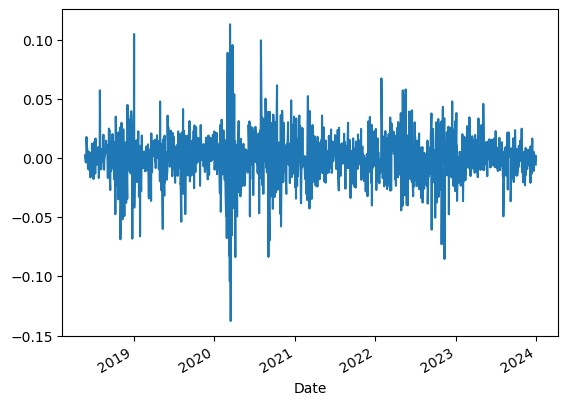

In [14]:
dfin['Strategie'] = dfin['Positie'].shift(1) * dfin['Log_opbrengst']
dfin['Strategie'].plot()

Als we de log-opbrengst vergelijken met de strategie, lijken we het veel slechter te doen dan enkel het aandeel te kopen en te houden:

In [15]:
dfin[['Log_opbrengst', 'Strategie']].sum()

Log_opbrengst    1.456195
Strategie        0.265720
dtype: float64

Terug omgezet naar de eigenlijke waarde vermits we een log-transformatie hebben toegepast:

In [16]:
dfin[['Log_opbrengst', 'Strategie']].sum().apply(np.exp)

Log_opbrengst    4.289604
Strategie        1.304370
dtype: float64

We kunnen de cumulatieve opbrengst ook visualiseren overheen de tijd, onze strategie doet het niet al te best:

<Axes: xlabel='Date'>

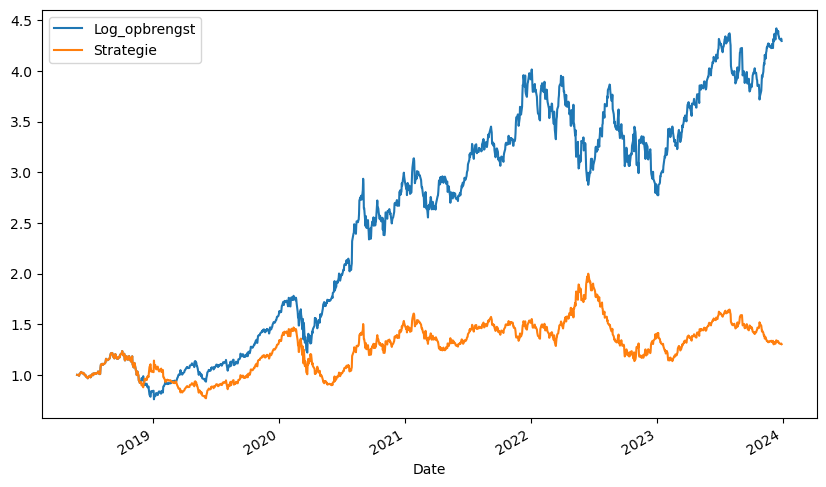

In [17]:
dfin[['Log_opbrengst', 'Strategie']].dropna().cumsum().apply(np.exp).plot(figsize=(10, 6))

De strategie kan ook visueel gemaakt worden door de posities aan te duiden op de tijdsreeks:

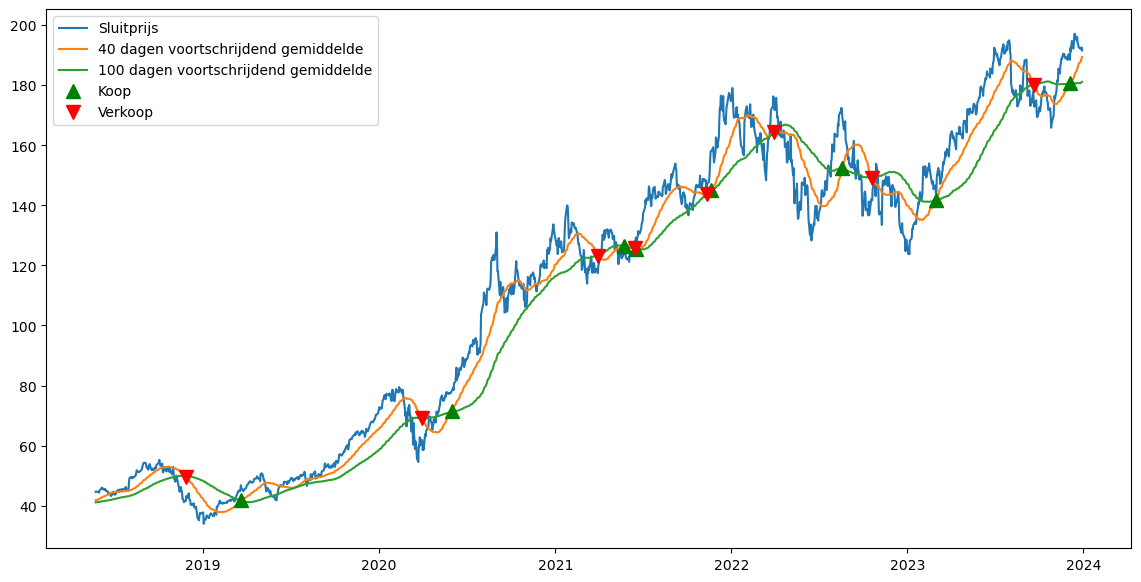

In [18]:
fig, ax = plt.subplots(figsize=(14, 7))

# Plot closing price
ax.plot(dfin.index, dfin['Close'], label='Sluitprijs')

# Plot short and long moving averages
ax.plot(dfin['Close_sma_40'], label='40 dagen voortschrijdend gemiddelde')
ax.plot(dfin['Close_sma_100'], label='100 dagen voortschrijdend gemiddelde')

# Plot buy signals
ax.plot(dfin.loc[dfin['Aanpassing'] > 1].index, dfin['Close_sma_40'][dfin['Aanpassing'] > 1], '^', markersize=10, color='g', lw=0, label='Koop')

# Plot sell signals
ax.plot(dfin.loc[dfin['Aanpassing'] < -1].index, dfin['Close_sma_40'][dfin['Aanpassing'] < -1], 'v', markersize=10, color='r', lw=0, label='Verkoop')

# Show the plot
ax.legend()
plt.show()